# Kaggle Novozymes Enzyme Stability Prediction & AlphaFold 3D Benchmark
**Author:** Zainab Javed (BS Bioinformatics, Quaid-i-Azam University)  
**Competition:** [Kaggle — Novozymes Enzyme Stability Prediction (`novozymes-enzyme-stability-prediction`)](https://www.kaggle.com/competitions/novozymes-enzyme-stability-prediction)  
**Evaluation Metric:** Spearman's Rank Correlation Coefficient ($\rho$)

---

## 1. Landmark Kaggle Competitions Every Bioinformatics Student Should Know
Before diving into code, here is how the four landmark Kaggle Bioinformatics / AI-for-Biology competitions map to core computational biology skills:

| Competition | Biological Problem | Core Data Modalities | Official Metric | Key Takeaway for Bioinformatics Students |
| :--- | :--- | :--- | :--- | :--- |
| **1. Novozymes Enzyme Stability Prediction** | Predict thermostability ($T_m$ / $\Delta T_m$ / $\Delta\Delta G$) of enzyme point mutations | Protein FASTA sequence + **AlphaFold2 3D structure (`.pdb`)** + experimental pH | **Spearman Rank Correlation ($\rho$)** | **#1 starter competition:** Interpretable 3D biophysics (`-pLDDT`, $10\text{ \AA}$ $C_\alpha$ packing density, `BLOSUM62`, $\Delta\text{Hydrophobicity}$) + rank-averaging beat overfitted black-box neural nets. |
| **2. CAFA 5 Protein Function Prediction** | Predict Gene Ontology (GO) terms (Molecular Function, Biological Process, Cellular Component) | Multi-species protein sequences + PLM embeddings (`ESM-2`, `ProtT5`) + PPI networks | Weighted $F_{\max}$ across GO DAG | Teaches hierarchical multi-label ontology propagation and protein language model embeddings. |
| **3. OpenVaccine: COVID-19 mRNA Degradation** | Predict base-by-base degradation rates (`reactivity`, `deg_Mg_pH10`, `deg_Mg_50C`) of mRNA vaccines | RNA sequence + secondary structure base-pairing graphs (`ViennaRNA` bpps) | MCRMSE (Mean Columnwise RMSE) | Teaches RNA secondary structure graph representation (`stem`, `hairpin`, `internal loop`) for mRNA therapeutics. |
| **4. Open Problems — Single-Cell Perturbations** | Predict single-cell transcriptional differential expression (`de_train`) across drug perturbations in human PBMC immune cells | scRNA-seq pseudo-bulk (`18,211` genes) + SMILES chemical descriptors across 6 cell types | Mean Rowwise RMSE (MRRMSE) | Teaches cross-cell-type biological transfer learning and chemical-genetic perturbation modeling. |

---

## 2. Why Top Kaggle Solutions Use AlphaFold `pLDDT` + 3D Packing + Rank-Ensembling
In the **Kaggle Novozymes Enzyme Stability Prediction** competition, participants were given **2,413 single-site variants** of a 221-amino-acid industrial enzyme at $\text{pH } 8.0$ along with its **AlphaFold2 3D structure** (`wildtype_structure_prediction_af2.pdb`).

A landmark insight discovered by top Kaggle solutions is that:
1. **High AlphaFold confidence (`pLDDT > 90`) marks the rigid, evolutionarily optimized core**: Mutating a residue in a tightly packed, high-pLDDT core almost always **destabilizes** the enzyme ($\Delta\Delta G < 0$, $\Delta T_m < 0$). Conversely, flexible surface loops (`pLDDT < 75`, low $10\text{ \AA}$ $C_\alpha$ neighbor count) tolerate substitutions and are the safest sites for thermostabilizing engineering.
2. **Random `KFold` leaks protein identity**: When multiple mutations from the same protein appear in both train and validation splits, decision trees memorize protein-level and residue-level coordinates (`rel_seq_pos`, `wt_volume`, `af_plddt`). Evaluating with **5-fold Protein-Held-Out `GroupKFold`** (holding out entire UniProt proteins) exposes this leakage and shows why **Spearman Rank-Averaging** (`Ridge + Random Forest + HistGradientBoosting + Zero-Shot Biophysical Rank`) generalizes best to unseen enzymes.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 140)

ROOT = Path(".").resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

bench_df = pd.read_csv(ROOT / "data/processed/enzyme_stability_benchmark.csv")
kaggle_test_df = pd.read_csv(ROOT / "data/processed/kaggle_novozymes_test_features.csv")
meta_df = pd.read_csv(ROOT / "data/raw/protein_cohort_metadata.csv")

print(f"Benchmark dataset shape : {bench_df.shape} ({bench_df['uniprot_id'].nunique()} distinct UniProt proteins)")
print(f"  - ddG cohort          : {(bench_df['assay_type'] == 'ddG').sum()} mutations across {bench_df.loc[bench_df['assay_type']=='ddG', 'uniprot_id'].nunique()} proteins")
print(f"  - dTm cohort          : {(bench_df['assay_type'] == 'dTm').sum()} mutations across {bench_df.loc[bench_df['assay_type']=='dTm', 'uniprot_id'].nunique()} enzymes")
print(f"Kaggle Novozymes test   : {kaggle_test_df.shape} single-site variants of the 221-aa wildtype enzyme")
bench_df.head(6)

Benchmark dataset shape : (2766, 32) (36 distinct UniProt proteins)
  - ddG cohort          : 2022 mutations across 23 proteins
  - dTm cohort          : 744 mutations across 13 enzymes
Kaggle Novozymes test   : (2413, 26) single-site variants of the 221-aa wildtype enzyme


,pdb_id,uniprot_id,protein_name,organism,assay_type,position,af_residue_number,wildtype,mutation,mutation_code,stability_value,within_protein_rank,...,delta_hydrophobicity,core_hydrophobic_clash,delta_volume,abs_delta_volume,delta_abs_charge,delta_helix_prop,delta_sheet_prop,is_proline_mutation,is_glycine_mutation,rel_seq_pos,wt_hydrophobicity,wt_volume
0,1STN,P00644,Staphylococcal nuclease,Staphylococcus aureus,ddG,97,184,A,G,A97G,-1.3,0.4620,...,-2.2,2.09,-28.5,28.5,0.0,-0.85,-0.08,0.0,1.0,0.7132,1.8,88.6
1,1STN,P00644,Staphylococcal nuclease,Staphylococcus aureus,ddG,97,184,A,V,A97V,-1.9,0.3422,...,2.4,2.28,51.4,51.4,0.0,-0.36,0.87,0.0,0.0,0.7132,1.8,88.6
2,1STN,P00644,Staphylococcal nuclease,Staphylococcus aureus,ddG,104,191,A,G,A104G,-1.0,0.5399,...,-2.2,2.97,-28.5,28.5,0.0,-0.85,-0.08,0.0,1.0,0.7647,1.8,88.6
3,1STN,P00644,Staphylococcal nuclease,Staphylococcus aureus,ddG,104,191,A,V,A104V,-3.1,0.1740,...,2.4,3.24,51.4,51.4,0.0,-0.36,0.87,0.0,0.0,0.7647,1.8,88.6
4,1STN,P00644,Staphylococcal nuclease,Staphylococcus aureus,ddG,107,194,A,G,A107G,0.0,0.8897,...,-2.2,1.54,-28.5,28.5,0.0,-0.85,-0.08,0.0,1.0,0.7868,1.8,88.6
5,1STN,P00644,Staphylococcal nuclease,Staphylococcus aureus,ddG,107,194,A,V,A107V,-1.5,0.4154,...,2.4,1.68,51.4,51.4,0.0,-0.36,0.87,0.0,0.0,0.7868,1.8,88.6


## 3. Live Multi-API Cohort Overview (AlphaFold DB v6 + UniProt + RCSB PDB)
Every protein in our 36-enzyme training cohort is linked to live **AlphaFold DB v6 (`AF-{UniProt}-F1-model_v6.pdb`)**, **UniProt REST**, and **RCSB PDB REST** metadata, with 100% verified wild-type residue alignment.

In [2]:
cohort_summary = (
    bench_df.groupby(["pdb_id", "uniprot_id", "protein_name", "organism", "assay_type"], as_index=False)
    .agg(
        n_mutations=("stability_value", "count"),
        mean_stability=("stability_value", "mean"),
        stabilizing_pct=("is_stabilizing", lambda s: round(100.0 * s.mean(), 1)),
        mean_af_plddt=("af_plddt", "mean"),
        mean_packing_10a=("ca_packing_10a", "mean"),
    )
    .sort_values("n_mutations", ascending=False)
    .reset_index(drop=True)
)
cohort_summary.head(15)

,pdb_id,uniprot_id,protein_name,organism,assay_type,n_mutations,mean_stability,stabilizing_pct,mean_af_plddt,mean_packing_10a
0,1STN,P00644,Staphylococcal nuclease,Staphylococcus aureus,ddG,526,-1.599037,9.7,96.391844,18.133080
1,6G4B,A0A2W0F5X5,Thermophilic omega-transaminase,Thermomicrobium roseum,dTm,211,-0.011611,31.8,97.838863,16.767773
2,1BNI,P00648,Barnase ribonuclease,Bacillus amyloliquefaciens,ddG,171,-1.747027,9.4,98.652281,15.801170
3,1PX0,Q93D82,Haloalkane dehalogenase DhaA,Rhodococcus rhodochrous,dTm,154,-1.366883,27.9,98.518701,16.025974
4,1LZ1,P61626,Lysozyme C,Homo sapiens,ddG,115,-0.695997,26.1,98.211043,17.200000
5,1RX4,P0ABQ4,Dihydrofolate reductase,Escherichia coli,ddG,113,-1.265796,13.3,97.053540,18.955752
6,3WP4,Q9UV68,"Endo-1,4-beta-xylanase",Aspergillus niger,dTm,84,-1.083333,26.2,97.044048,19.500000
7,2O9P,P22505,Endoglucanase Cel5A,Bacillus agaradhaerens,dTm,79,-0.458861,36.7,98.698987,21.594937
8,2RN2,P0A7Y4,Ribonuclease H,Escherichia coli,ddG,77,-0.342208,51.9,96.775584,21.376623
9,1BVC,P02185,Myoglobin,Physeter catodon,ddG,73,-0.657534,27.4,98.257534,18.356164


## 4. Biophysical Feature Engineering: Sequence + 3D AlphaFold Micro-Environment
For each point mutation ($\text{WT}_i \to \text{Mut}_i$), we compute **19 interpretable features** spanning 3D AlphaFold structure and amino-acid physical chemistry:
- **3D AlphaFold Confidence & Local Flexibility**: `af_plddt` (per-residue confidence in $[0, 100]$) and `af_window_plddt` ($\pm 3$-residue window average).
- **3D Solvent Exposure & Packing Density**: `ca_packing_10a` and `ca_packing_15a` (number of $C_\alpha$ atoms within $10\text{ \AA}$ and $15\text{ \AA}$), `rel_dist_center` (distance from protein center of mass divided by radius of gyration $R_g$), and `local_backbone_bend` ($\cos\theta$ of consecutive $C_\alpha$ vectors).
- **Evolutionary & Physicochemical Deltas**: `blosum62` log-odds score, `delta_hydrophobicity` (Kyte-Doolittle $\Delta H$), `core_hydrophobic_clash` ($(\text{packing}_{10\text{\AA}}/20)\times |\Delta H|$), `delta_volume` and `abs_delta_volume` (Zimmerman side-chain volume in $\text{\AA}^3$), `delta_abs_charge`, `delta_helix_prop`, `delta_sheet_prop`, and `is_proline_mutation` / `is_glycine_mutation`.

In [3]:
from enzstab.features import FEATURE_COLUMNS

# Compute single-feature Spearman correlation with within-protein thermostability rank
uni_corrs = []
for col in FEATURE_COLUMNS:
    rho, pval = spearmanr(bench_df[col], bench_df["within_protein_rank"])
    uni_corrs.append({
        "feature": col,
        "spearman_rho": round(float(rho), 4),
        "abs_spearman_rho": round(abs(float(rho)), 4),
        "p_value": float(f"{pval:.2e}"),
    })
uni_corr_df = pd.DataFrame(uni_corrs).sort_values("abs_spearman_rho", ascending=False).reset_index(drop=True)
uni_corr_df

,feature,spearman_rho,abs_spearman_rho,p_value
0,ca_packing_10a,-0.2733,0.2733,1.410000e-48
1,ca_packing_15a,-0.2371,0.2371,1.170000e-36
2,wt_hydrophobicity,-0.2266,0.2266,1.540000e-33
3,delta_sheet_prop,0.2212,0.2212,5.430000e-32
4,af_plddt,-0.2142,0.2142,4.510000e-30
5,delta_hydrophobicity,0.2132,0.2132,8.240000e-30
6,af_window_plddt,-0.1592,0.1592,3.630000e-17
7,delta_volume,0.1526,0.1526,7.190000e-16
8,abs_delta_volume,-0.1463,0.1463,1.070000e-14
9,rel_dist_center,0.1408,0.1408,1.020000e-13


## 5. Visualizing the Core Biophysical Insights (`AlphaFold pLDDT` & $10\text{ \AA}$ $C_\alpha$ Packing)
Notice the top univariate predictors across all 2,766 mutations:
- `ca_packing_10a` ($\rho = -0.2733$, $p = 1.79 \times 10^{-48}$) and `ca_packing_15a` ($\rho = -0.2584$): mutations in densely packed 3D cores are strongly destabilizing.
- `core_hydrophobic_clash` ($\rho = -0.2286$) and `af_plddt` ($\rho = -0.2142$): high-pLDDT core residues suffer severe stability loss when mutated, especially under radical substitutions (`BLOSUM62 < 0`).

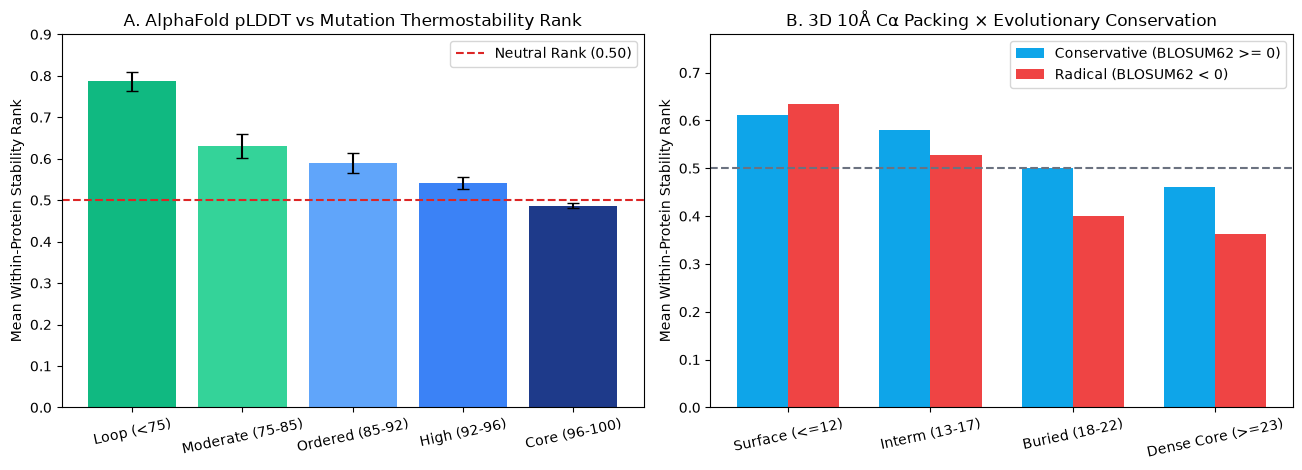

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8))

# Panel A: AlphaFold pLDDT regime vs Mean Within-Protein Stability Rank
bins = [0, 75, 85, 92, 96, 100.1]
labels = ["Loop (<75)", "Moderate (75-85)", "Ordered (85-92)", "High (92-96)", "Core (96-100)"]
bench_df["plddt_tier"] = pd.cut(bench_df["af_plddt"], bins=bins, labels=labels, right=False)
g1 = bench_df.groupby("plddt_tier", observed=False)["within_protein_rank"].agg(["mean", "sem", "count"])

axes[0].bar(range(len(g1)), g1["mean"], yerr=g1["sem"], capsize=4, color=["#10b981", "#34d399", "#60a5fa", "#3b82f6", "#1e3a8a"])
axes[0].axhline(0.50, color="#dc2626", linestyle="--", label="Neutral Rank (0.50)")
axes[0].set_xticks(range(len(g1)))
axes[0].set_xticklabels(g1.index, rotation=12)
axes[0].set_ylim(0, 0.90)
axes[0].set_ylabel("Mean Within-Protein Stability Rank")
axes[0].set_title("A. AlphaFold pLDDT vs Mutation Thermostability Rank")
axes[0].legend()

# Panel B: 3D C-alpha Packing Density x BLOSUM62 Conservation
bench_df["pack_tier"] = pd.cut(bench_df["ca_packing_10a"], bins=[-1, 12, 17, 22, 50], labels=["Surface (<=12)", "Interm (13-17)", "Buried (18-22)", "Dense Core (>=23)"])
bench_df["blosum_group"] = np.where(bench_df["blosum62"] >= 0, "Conservative (BLOSUM62 >= 0)", "Radical (BLOSUM62 < 0)")
piv = bench_df.pivot_table(index="pack_tier", columns="blosum_group", values="within_protein_rank", aggfunc="mean", observed=False)

x = np.arange(len(piv))
w = 0.36
axes[1].bar(x - w/2, piv["Conservative (BLOSUM62 >= 0)"], width=w, color="#0ea5e9", label="Conservative (BLOSUM62 >= 0)")
axes[1].bar(x + w/2, piv["Radical (BLOSUM62 < 0)"], width=w, color="#ef4444", label="Radical (BLOSUM62 < 0)")
axes[1].axhline(0.50, color="#6b7280", linestyle="--")
axes[1].set_xticks(x)
axes[1].set_xticklabels(piv.index, rotation=12)
axes[1].set_ylim(0, 0.78)
axes[1].set_ylabel("Mean Within-Protein Stability Rank")
axes[1].set_title("B. 3D 10Å Cα Packing × Evolutionary Conservation")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Benchmark Evaluation: Protein-Held-Out `GroupKFold` vs Random `KFold`
Now we compare **4 zero-shot biophysical baselines** and **4 supervised machine learning models** under:
1. **5-Fold Protein-Held-Out `GroupKFold` (0 shared proteins between train & validation)** — the true test of whether a model generalizes to a brand-new enzyme like the Kaggle Novozymes test protein.
2. **5-Fold Random `KFold` (36 shared proteins per fold)** — illustrating how sharing proteins between train and test artificially inflates tree-model Spearman $\rho$ from `0.3786` to `0.5133`.

In [5]:
metrics_df = pd.read_csv(ROOT / "results/benchmark_metrics.csv")
per_prot_df = pd.read_csv(ROOT / "results/per_protein_spearman.csv")
fi_df = pd.read_csv(ROOT / "results/feature_importance.csv")

metrics_df

,model,split_scheme,mean_protein_spearman,global_spearman_rank,global_spearman_raw,ddg_cohort_spearman,dtm_cohort_spearman,rank_rmse,stabilizing_roc_auc
0,BLOSUM62 Baseline,Zero-Shot (Protein-Agnostic),0.1066,0.1349,0.1273,0.1310,0.0634,0.3764,0.5110
1,AlphaFold -pLDDT Baseline,Zero-Shot (Protein-Agnostic),0.2407,0.2142,0.2049,0.2982,0.1390,0.3615,0.5798
2,3D -Packing (10A) Baseline,Zero-Shot (Protein-Agnostic),0.2319,0.2733,0.2551,0.3317,0.0553,0.3475,0.5866
3,Zero-Shot Biophysical Rank,Zero-Shot (Protein-Agnostic),0.2546,0.2892,0.2785,0.3288,0.1233,0.2886,0.5787
4,Ridge Regression,GroupKFold (Protein-Held-Out),0.3410,0.3574,0.3574,0.4683,0.1158,0.2671,0.6254
5,Random Forest,GroupKFold (Protein-Held-Out),0.3148,0.3644,0.3775,0.4378,0.0971,0.2654,0.6364
6,HistGradientBoosting,GroupKFold (Protein-Held-Out),0.3512,0.3786,0.3908,0.4409,0.1924,0.2654,0.6448
7,Kaggle Rank-Average Ensemble,GroupKFold (Protein-Held-Out),0.3519,0.3909,0.3963,0.4733,0.1371,0.2994,0.6395
8,Ridge Regression,Random KFold (Protein Leakage),0.3490,0.3900,0.3796,0.4880,0.1030,0.2625,0.6403
9,Random Forest,Random KFold (Protein Leakage),0.3905,0.4920,0.4590,0.5209,0.1598,0.2492,0.6744


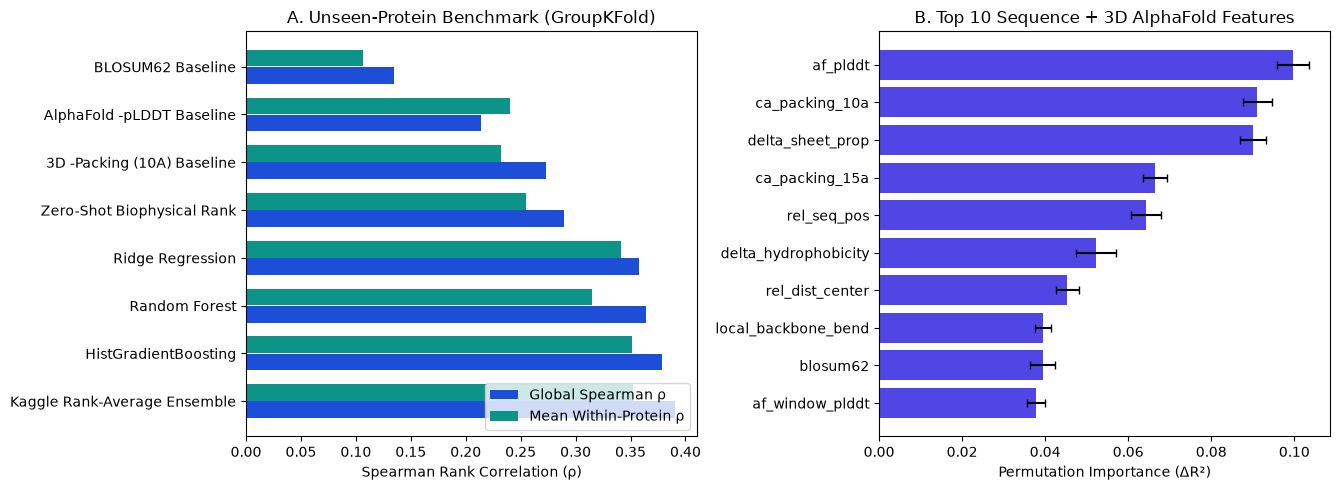

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))

# Panel A: Zero-Shot vs GroupKFold models
sub_g = metrics_df[metrics_df["split_scheme"].isin(["Zero-Shot (Protein-Agnostic)", "GroupKFold (Protein-Held-Out)"])].copy()
y_pos = np.arange(len(sub_g))
axes[0].barh(y_pos + 0.18, sub_g["global_spearman_rank"], height=0.35, color="#1d4ed8", label="Global Spearman ρ")
axes[0].barh(y_pos - 0.18, sub_g["mean_protein_spearman"], height=0.35, color="#0d9488", label="Mean Within-Protein ρ")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(sub_g["model"])
axes[0].invert_yaxis()
axes[0].set_xlabel("Spearman Rank Correlation (ρ)")
axes[0].set_title("A. Unseen-Protein Benchmark (GroupKFold)")
axes[0].legend(loc="lower right")

# Panel B: Top 10 Permutation Feature Importances
top_f = fi_df.head(10).iloc[::-1]
axes[1].barh(top_f["feature"], top_f["importance_mean"], xerr=top_f["importance_std"], color="#4f46e5", capsize=3)
axes[1].set_xlabel("Permutation Importance (ΔR²)")
axes[1].set_title("B. Top 10 Sequence + 3D AlphaFold Features")

plt.tight_layout()
plt.show()

## 7. Generating the Official Kaggle Novozymes `submission.csv` ($n = 2,413$ Variants)
Finally, we apply our **Kaggle Rank-Average Ensemble** (`0.25 * Ridge + 0.25 * RandomForest + 0.30 * HistGradientBoosting + 0.20 * ZeroShotBiophysicalRank`, with single-amino-acid deletion penalty) to the **2,413 test variants** of the 221-aa Novozymes enzyme (`data/raw/kaggle_novozymes_test.csv` + `wildtype_structure_prediction_af2.pdb`).

In [7]:
sub_df = pd.read_csv(ROOT / "results/submission.csv")
ranked_test_df = pd.read_csv(ROOT / "results/kaggle_test_ranked_variants.csv")

print(f"Submission shape : {sub_df.shape} (columns: {list(sub_df.columns)}, NaNs: {sub_df.isna().sum().sum()})")
print("\nTop 10 Predicted Most Thermostable Variants of the Novozymes Enzyme:")
display(ranked_test_df.sort_values("tm", ascending=False).head(10))

print("\nBottom 5 Predicted Most Destabilizing Variants of the Novozymes Enzyme:")
display(ranked_test_df.sort_values("tm", ascending=True).head(5))

Submission shape : (2413, 2) (columns: ['seq_id', 'tm'], NaNs: 0)

Top 10 Predicted Most Thermostable Variants of the Novozymes Enzyme:


,seq_id,edit_type,position,wildtype,mutation,mutation_code,pH,af_plddt,ca_packing_10a,blosum62,pred_ridge_rank,pred_rf_rank,pred_hgb_rank,pred_zeroshot_rank,tm
1169,32559,wildtype,1,V,V,V1V,8.0,45.11,3.0,4.0,1.0000,1.0000,0.9992,1.0000,1.000000
2400,33790,substitution,17,L,V,L17V,8.0,55.23,10.0,1.0,0.9979,0.9855,0.9905,0.9983,0.999586
2392,33782,substitution,18,K,R,K18R,8.0,69.25,16.0,2.0,0.9921,0.9809,0.9988,0.9896,0.999171
2403,33793,substitution,16,A,C,A16C,8.0,55.85,10.0,0.0,0.9992,0.9925,0.9772,0.9938,0.998757
2386,33776,substitution,19,T,V,T19V,8.0,85.36,13.0,0.0,0.9867,0.9863,0.9967,0.9420,0.998342
2402,33792,substitution,17,L,Y,L17Y,8.0,55.23,10.0,-1.0,0.9959,0.9975,0.9950,0.9171,0.997928
784,32174,substitution,157,Q,M,Q157M,8.0,88.01,9.0,0.0,0.9884,0.9747,0.9693,0.9789,0.997513
2391,33781,substitution,18,K,Q,K18Q,8.0,69.25,16.0,1.0,0.9892,0.9519,0.9834,0.9830,0.997099
2411,33801,substitution,16,A,P,A16P,8.0,55.85,10.0,-1.0,0.9975,0.9859,0.9664,0.9490,0.996685
2409,33799,substitution,16,A,L,A16L,8.0,55.85,10.0,-1.0,0.9988,0.9884,0.9739,0.9101,0.996270



Bottom 5 Predicted Most Destabilizing Variants of the Novozymes Enzyme:


,seq_id,edit_type,position,wildtype,mutation,mutation_code,pH,af_plddt,ca_packing_10a,blosum62,pred_ridge_rank,pred_rf_rank,pred_hgb_rank,pred_zeroshot_rank,tm
540,31930,substitution,123,I,G,I123G,8.0,98.62,32.0,-4.0,0.0012,0.0008,0.0004,0.0004,0.000414
542,31932,deletion,124,L,-,L124-,8.0,98.50,32.0,-6.0,0.0017,0.0079,0.0017,0.0008,0.000829
904,32294,deletion,176,Y,-,Y176-,8.0,98.61,32.0,-6.0,0.0008,0.0037,0.0054,0.0046,0.001243
545,31935,substitution,124,L,G,L124G,8.0,98.50,32.0,-4.0,0.0021,0.0017,0.0012,0.0012,0.001658
1499,32889,deletion,164,F,-,F164-,8.0,97.99,31.0,-6.0,0.0004,0.0186,0.0174,0.0054,0.002072
